In [26]:
import pandas as pd


In [27]:
for arxeio in ["data-19412973.csv", "data-19413497.csv"]:
    df = pd.read_csv(arxeio, sep=None, engine="python")
    print(arxeio, "-> γραμμές, στήλες:", df.shape)
    print(df.head(5))
    print()

data-19412973.csv -> γραμμές, στήλες: (23061, 7)
  REPORTER_LAB PARTNER_LAB                                        PRODUCT_LAB  \
0       Greece     Andorra  Animal or vegetable fats and oils and their cl...   
1       Greece     Andorra  Prepared foodstuffs; beverages, spirits and vi...   
2       Greece     Andorra  Prepared foodstuffs; beverages, spirits and vi...   
3       Greece     Andorra  Prepared foodstuffs; beverages, spirits and vi...   
4       Greece     Andorra  Products of the chemical or allied industries ...   

  FLOW_LAB  PERIOD INDICATORS_LAB  INDICATOR_VALUE  
0   IMPORT  202505      VALUE_EUR           148583  
1   EXPORT  202501      VALUE_EUR            37669  
2   EXPORT  202503      VALUE_EUR            33906  
3   EXPORT  202506      VALUE_EUR            36235  
4   IMPORT  202503      VALUE_EUR            29560  

data-19413497.csv -> γραμμές, στήλες: (20746, 7)
  REPORTER_LAB PARTNER_LAB                                        PRODUCT_LAB  \
0       Greece 

In [28]:
df = pd.read_csv("data-19412973.csv")
print("γραμμέ, στήλες:", df.shape)
print()
print("Στήλες:",list(df.columns))
print()
print("Μήνες:", sorted(df["PERIOD"].unique()))
print()
print(df.head(5).to_string())

γραμμέ, στήλες: (23061, 7)

Στήλες: ['REPORTER_LAB', 'PARTNER_LAB', 'PRODUCT_LAB', 'FLOW_LAB', 'PERIOD', 'INDICATORS_LAB', 'INDICATOR_VALUE']

Μήνες: [np.int64(202501), np.int64(202502), np.int64(202503), np.int64(202504), np.int64(202505), np.int64(202506)]

  REPORTER_LAB PARTNER_LAB                                                                                                                  PRODUCT_LAB FLOW_LAB  PERIOD INDICATORS_LAB  INDICATOR_VALUE
0       Greece     Andorra  Animal or vegetable fats and oils and their cleavage products; prepared edible fats; animal or vegetable waxes (chapter 15)   IMPORT  202505      VALUE_EUR           148583
1       Greece     Andorra        Prepared foodstuffs; beverages, spirits and vinegar; tobacco and manufactured tobacco substitutes (chapters 16 to 24)   EXPORT  202501      VALUE_EUR            37669
2       Greece     Andorra        Prepared foodstuffs; beverages, spirits and vinegar; tobacco and manufactured tobacco substitutes (chap

In [29]:
import pandas as pd

df = pd.read_csv("data-19412973.csv")
print("Γραμμές, στήλες:", df.shape)
print()

print("Μήνες:", sorted(int(m) for m in df["PERIOD"].unique()))
print("Εταίροι:", df["PARTNER_LAB"].nunique())
print("Ομάδες προϊόντων:", df["PRODUCT_LAB"].nunique())
print()

maska = df["PARTNER_LAB"].str.contains(
    "EU|Extra|Intra|World|Euro|Total|EFTA|OPEC|ACP|Mercosur|ASEAN|confiden|Not ",
    case=False, na=False)
print("Πιθανές συγκεντρωτικές γραμμές:")
for onoma in sorted(df.loc[maska, "PARTNER_LAB"].unique()):
    print("-", onoma)

Γραμμές, στήλες: (23061, 7)

Μήνες: [202501, 202502, 202503, 202504, 202505, 202506]
Εταίροι: 229
Ομάδες προϊόντων: 22

Πιθανές συγκεντρωτικές γραμμές:
- All countries of the world
- Bonaire, Sint Eustatius and Saba
- Ceuta (incl. Melilla 'XL' -> 1998)
- Countries and territories not specified for commercial or military reasons in the framework of extra-Union trade
- Countries and territories not specified for commercial or military reasons in the framework of intra-Union trade
- Countries and territories not specified within the framework of extra-Union trade
- Countries and territories not specified within the framework of intra-Union trade
- Extra-EU
- Extra-EU27 (from 2020)
- Extra-euro area
- Extra-euro area - 21 countries (from 2026)
- Intra-EU
- Intra-EU27 (from 2020)
- Intra-euro area
- Intra-euro area - 21 countries (from 2026)
- Stores and provisions within the framework of extra-Union trade
- Stores and provisions within the framework of intra-Union trade


In [30]:
df["typos"] = "χώρα"
df.loc[df["PARTNER_LAB"].str.startswith(("Extra-", "Intra-")), "typos"] = "ομάδα"
df.loc[df["PARTNER_LAB"] == "All countries of the world", "typos"] = "σύνολο"
df.loc[df["PARTNER_LAB"].str.startswith(
    ("Countries and territories not specified", "Stores and provisions")), "typos"] = "ειδικό"

print(df["typos"].value_counts())
print()

pivot = df.pivot_table(index="FLOW_LAB", columns="typos",
                       values="INDICATOR_VALUE", aggfunc="sum") / 1e9
print("Αξία σε δισ. ευρώ (Ιαν-Ιουν 2025):")
print(pivot.round(2))

typos
χώρα      20585
ομάδα      2064
σύνολο      258
ειδικό      154
Name: count, dtype: int64

Αξία σε δισ. ευρώ (Ιαν-Ιουν 2025):
typos     ειδικό   ομάδα  σύνολο   χώρα
FLOW_LAB                               
EXPORT      0.03   96.51   24.13  24.10
IMPORT      0.15  163.93   40.98  40.84


Δισ. ευρώ ανά μήνα:
FLOW_LAB  EXPORT  IMPORT  ISOZYGIO
PERIOD                            
202501      4.12    6.95     -2.83
202502      4.07    6.50     -2.44
202503      3.95    7.11     -3.15
202504      3.83    6.63     -2.80
202505      4.17    6.51     -2.34
202506      3.96    7.14     -3.18


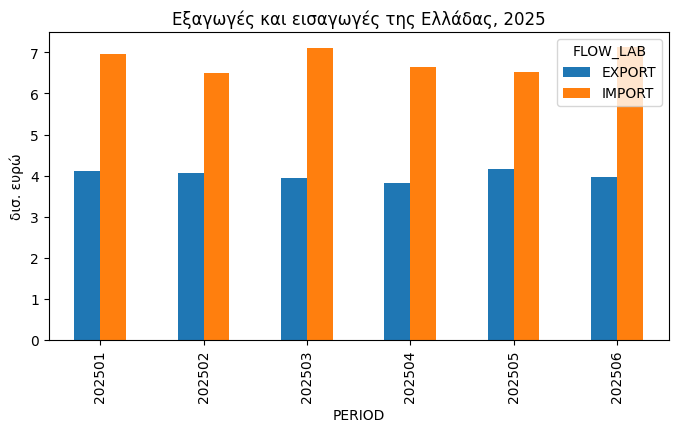

In [31]:
import matplotlib.pyplot as plt

xwres = df[df["typos"] == "χώρα"].copy()

mina = xwres.pivot_table(index="PERIOD", columns="FLOW_LAB",
                         values="INDICATOR_VALUE", aggfunc="sum") / 1e9
mina["ISOZYGIO"] = mina["EXPORT"] - mina["IMPORT"]

print("Δισ. ευρώ ανά μήνα:")
print(mina.round(2))

mina[["EXPORT", "IMPORT"]].plot(kind="bar", figsize=(8, 4))
plt.title("Εξαγωγές και εισαγωγές της Ελλάδας, 2025")
plt.ylabel("δισ. ευρώ")
plt.show()

In [32]:
import glob
import pandas as pd

arxeia = sorted(glob.glob("data-*.csv"))
print("Αρχεία:", arxeia)

df = pd.concat([pd.read_csv(a) for a in arxeia], ignore_index=True)
print("Γραμμές, στήλες:", df.shape)
print("Μήνες:", sorted(int(m) for m in df["PERIOD"].unique()))
print("Διπλές γραμμές:", df.duplicated().sum())

Αρχεία: ['data-19412973.csv', 'data-19413497.csv']
Γραμμές, στήλες: (43807, 7)
Μήνες: [202501, 202502, 202503, 202504, 202505, 202506, 202507, 202508, 202509, 202510, 202511, 202512]
Διπλές γραμμές: 0


Αριθμός μηνών: 12
Δισ. ευρώ, όλο το 2025 (Ιαν-Δεκ):
typos      χώρα  ειδικό  σύνολο
FLOW_LAB                       
EXPORT    48.57    0.09   24.13
IMPORT    80.91    1.56   40.98
FLOW_LAB  EXPORT  IMPORT  ISOZYGIO
PERIOD                            
202501      4.12    6.95     -2.83
202502      4.07    6.50     -2.44
202503      3.95    7.11     -3.15
202504      3.83    6.63     -2.80
202505      4.17    6.51     -2.34
202506      3.96    7.14     -3.18
202507      4.34    7.35     -3.02
202508      3.36    5.47     -2.11
202509      4.24    6.96     -2.72
202510      4.28    6.88     -2.61
202511      4.09    6.93     -2.84
202512      4.16    6.48     -2.32


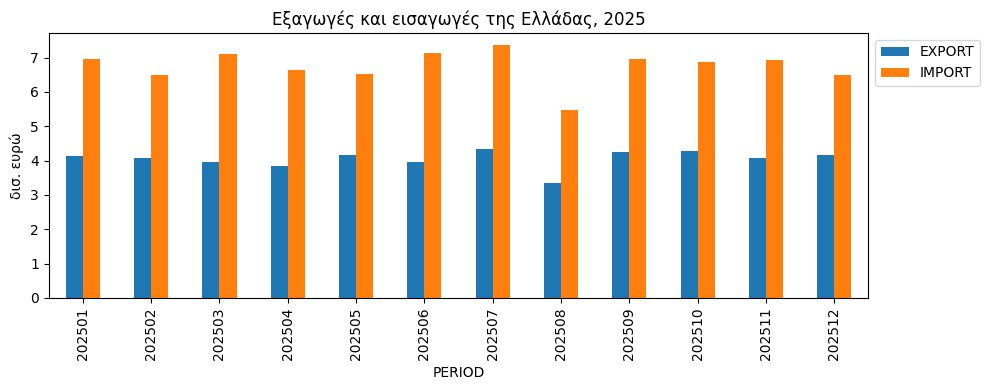

In [33]:
import matplotlib.pyplot as plt

print("Αριθμός μηνών:", df["PERIOD"].nunique())

# Ξεχωρίζουμε τις χώρες από τις συγκεντρωτικές γραμμές
df["typos"] = "χώρα"
df.loc[df["PARTNER_LAB"].str.startswith(("Extra-", "Intra-")), "typos"] = "ομάδα"
df.loc[df["PARTNER_LAB"] == "All countries of the world", "typos"] = "σύνολο"
df.loc[df["PARTNER_LAB"].str.startswith(
    ("Countries and territories not specified", "Stores and provisions")), "typos"] = "ειδικό"

# Έλεγχος: χώρες + ειδικό = σύνολο;
pivot = df.pivot_table(index="FLOW_LAB", columns="typos",
                       values="INDICATOR_VALUE", aggfunc="sum") / 1e9
print("Δισ. ευρώ, όλο το 2025 (Ιαν-Δεκ):")
print(pivot[["χώρα", "ειδικό", "σύνολο"]].round(2))

# Μηνιαίος πίνακας και γράφημα
xwres = df[df["typos"] == "χώρα"]
mina = xwres.pivot_table(index="PERIOD", columns="FLOW_LAB",
                         values="INDICATOR_VALUE", aggfunc="sum") / 1e9
mina["ISOZYGIO"] = mina["EXPORT"] - mina["IMPORT"]
print(mina.round(2))

mina[["EXPORT", "IMPORT"]].plot(kind="bar", figsize=(10, 4))
plt.title("Εξαγωγές και εισαγωγές της Ελλάδας, 2025")
plt.ylabel("δισ. ευρώ")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [38]:

# Ελεγχος συνολικων αξιων και εμπορικου ισοζυγιου

for typos in ["χώρα", "ειδικό", "σύνολο", "ομάδα"]:
    print("\nΚατηγορία:", typos)

    temp = df[df["typos"] == typos]

    apotelesmata = (
        temp.groupby("FLOW_LAB")["INDICATOR_VALUE"]
        .sum() / 1e9
    )

    print(apotelesmata.round(3))

# Ετήσια εικόνα με βάση τις εγγραφές χωρών
xwres = df[df["typos"] == "χώρα"]

etisia = (
    xwres.pivot_table(
        index="FLOW_LAB",
        values="INDICATOR_VALUE",
        aggfunc="sum"
    )["INDICATOR_VALUE"] / 1e9
)

eksagoges = etisia["EXPORT"]
eisagoges = etisia["IMPORT"]

print("\n--- ΕΤΗΣΙΟ ΕΜΠΟΡΙΚΟ ΙΣΟΖΥΓΙΟ ---")
print(f"Εξαγωγές: {eksagoges:.3f} δισ. ευρώ")
print(f"Εισαγωγές: {eisagoges:.3f} δισ. ευρώ")
print(f"Ισοζύγιο: {eksagoges - eisagoges:.3f} δισ. ευρώ")



Κατηγορία: χώρα
FLOW_LAB
EXPORT    48.566
IMPORT    80.914
Name: INDICATOR_VALUE, dtype: float64

Κατηγορία: ειδικό
FLOW_LAB
EXPORT    0.093
IMPORT    1.561
Name: INDICATOR_VALUE, dtype: float64

Κατηγορία: σύνολο
FLOW_LAB
EXPORT    24.127
IMPORT    40.982
Name: INDICATOR_VALUE, dtype: float64

Κατηγορία: ομάδα
FLOW_LAB
EXPORT     96.508
IMPORT    163.927
Name: INDICATOR_VALUE, dtype: float64

--- ΕΤΗΣΙΟ ΕΜΠΟΡΙΚΟ ΙΣΟΖΥΓΙΟ ---
Εξαγωγές: 48.566 δισ. ευρώ
Εισαγωγές: 80.914 δισ. ευρώ
Ισοζύγιο: -32.348 δισ. ευρώ


In [34]:
for a in arxeia:
    d = pd.read_csv(a)
    print(a)
    print("  γραμμές:", len(d), "| εταίροι:", d["PARTNER_LAB"].nunique())
    print("  μήνες:", sorted(int(m) for m in d["PERIOD"].unique()))
    print("  γραμμές 'All countries of the world':",
          (d["PARTNER_LAB"] == "All countries of the world").sum())
    print("  γραμμές που ξεκινούν με Extra-/Intra-:",
          d["PARTNER_LAB"].str.startswith(("Extra-", "Intra-")).sum())
    print()

data-19412973.csv
  γραμμές: 23061 | εταίροι: 229
  μήνες: [202501, 202502, 202503, 202504, 202505, 202506]
  γραμμές 'All countries of the world': 258
  γραμμές που ξεκινούν με Extra-/Intra-: 2064

data-19413497.csv
  γραμμές: 20746 | εταίροι: 219
  μήνες: [202507, 202508, 202509, 202510, 202511, 202512]
  γραμμές 'All countries of the world': 0
  γραμμές που ξεκινούν με Extra-/Intra-: 0



Top 10 - EXPORT (δισ. ευρώ, 2025)
PARTNER_LAB
Italy (incl. San Marino 'SM' -> 1993)                                                                                                                             4.46
Germany (incl. German Democratic Republic 'DD' from 1991)                                                                                                         3.79
Cyprus                                                                                                                                                            3.31
Bulgaria                                                                                                                                                          3.16
United States (incl. Navassa Island (part of 'UM') from 1995 -> 2000)                                                                                             2.40
Romania                                                                                                                

/var/folders/h5/x1qyd26j5c349ksnf_8cn0980000gn/T/ipykernel_7628/1900285570.py:14: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


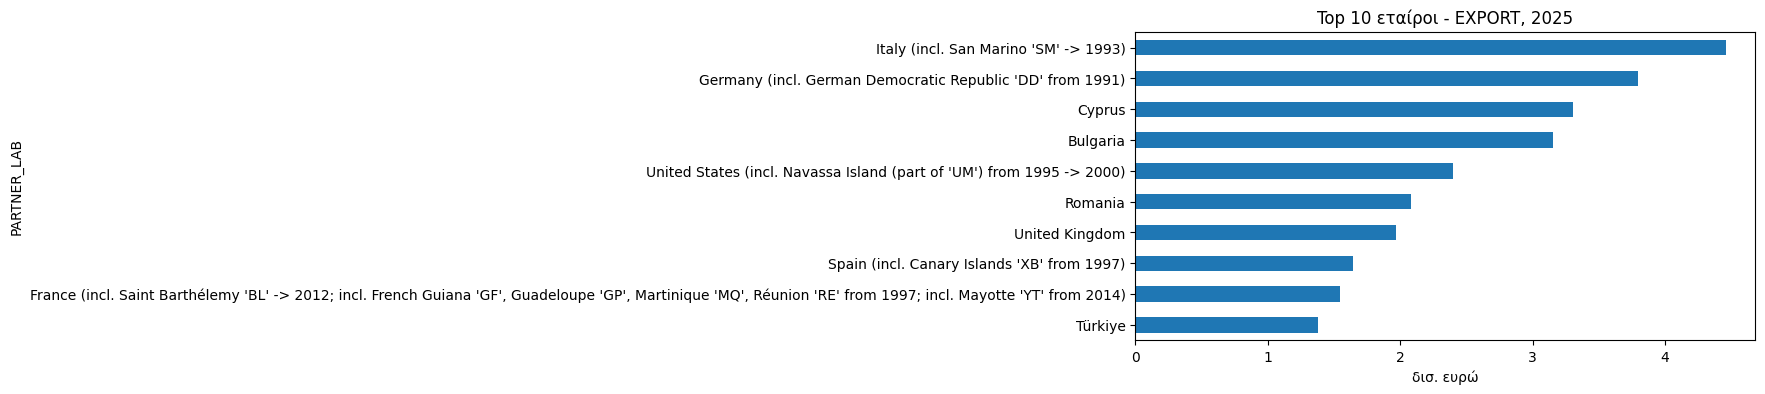

Top 10 - IMPORT (δισ. ευρώ, 2025)
PARTNER_LAB
Germany (incl. German Democratic Republic 'DD' from 1991)                                                                                                         9.52
Italy (incl. San Marino 'SM' -> 1993)                                                                                                                             7.46
China                                                                                                                                                             6.49
Netherlands                                                                                                                                                       5.08
France (incl. Saint Barthélemy 'BL' -> 2012; incl. French Guiana 'GF', Guadeloupe 'GP', Martinique 'MQ', Réunion 'RE' from 1997; incl. Mayotte 'YT' from 2014)    4.08
Iraq                                                                                                                   

/var/folders/h5/x1qyd26j5c349ksnf_8cn0980000gn/T/ipykernel_7628/1900285570.py:14: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


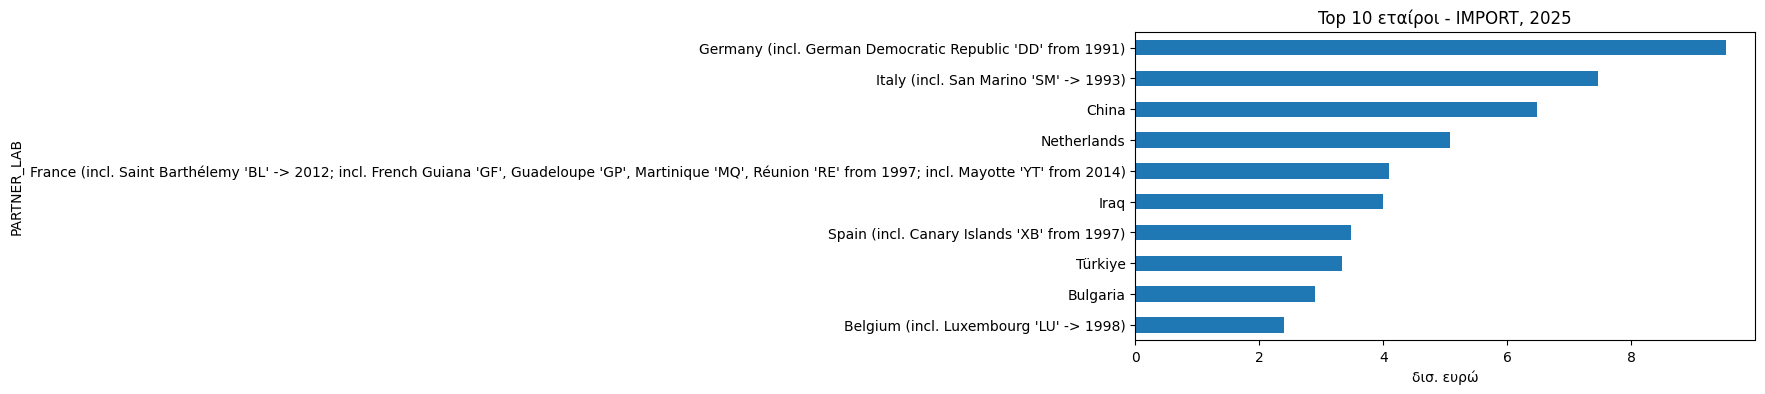

In [35]:
xwres = df[df["typos"] == "χώρα"]

for roi in ["EXPORT", "IMPORT"]:
    top = (xwres[xwres["FLOW_LAB"] == roi]
           .groupby("PARTNER_LAB")["INDICATOR_VALUE"].sum()
           .sort_values(ascending=False).head(10) / 1e9)
    print("Top 10 -", roi, "(δισ. ευρώ, 2025)")
    print(top.round(2))
    print()

    top.sort_values().plot(kind="barh", figsize=(8, 4))
    plt.title("Top 10 εταίροι - " + roi + ", 2025")
    plt.xlabel("δισ. ευρώ")
    plt.tight_layout()
    plt.show()

Top 10 - EXPORT (δισ. ευρώ, 2025)
EPAITEROS
Italy             4.46
Germany           3.79
Cyprus            3.31
Bulgaria          3.16
United States     2.40
Romania           2.08
United Kingdom    1.97
Spain             1.65
France            1.55
Türkiye           1.38
Name: INDICATOR_VALUE, dtype: float64



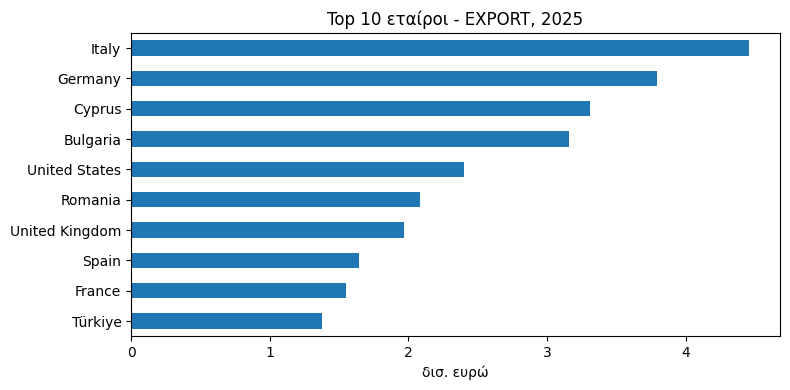

Top 10 - IMPORT (δισ. ευρώ, 2025)
EPAITEROS
Germany        9.52
Italy          7.46
China          6.49
Netherlands    5.08
France         4.08
Iraq           3.99
Spain          3.48
Türkiye        3.34
Bulgaria       2.90
Belgium        2.40
Name: INDICATOR_VALUE, dtype: float64



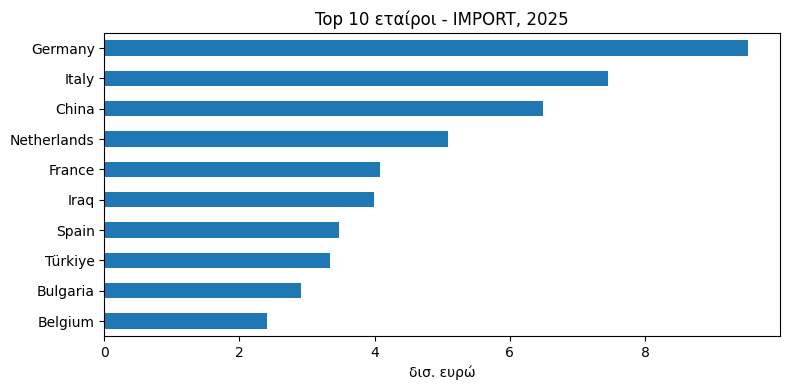

In [36]:
xwres = df[df["typos"] == "χώρα"].copy()
xwres["EPAITEROS"] = xwres["PARTNER_LAB"].str.split(" (", n=1, regex=False).str[0]

for roi in ["EXPORT", "IMPORT"]:
    top = (xwres[xwres["FLOW_LAB"] == roi]
           .groupby("EPAITEROS")["INDICATOR_VALUE"].sum()
           .sort_values(ascending=False).head(10) / 1e9)
    print("Top 10 -", roi, "(δισ. ευρώ, 2025)")
    print(top.round(2))
    print()

    top.sort_values().plot(kind="barh", figsize=(8, 4))
    plt.title("Top 10 εταίροι - " + roi + ", 2025")
    plt.xlabel("δισ. ευρώ")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

Top 10 κατηγορίες - EXPORT (δισ. ευρώ, 2025)
KATIGORIA
Mineral products                                 13.54
Base metals and articles of base metal            5.84
Products of the chemical or allied industries     5.25
Prepared foodstuffs; beverages, spirits and v     4.93
Machinery and mechanical appliances; electric     4.19
Live animals; animal products                     3.13
Vegetable products                                2.74
Plastics and articles thereof; rubber and art     1.67
Textiles and textile articles                     1.54
Animal or vegetable fats and oils and their c     1.10
Name: INDICATOR_VALUE, dtype: float64



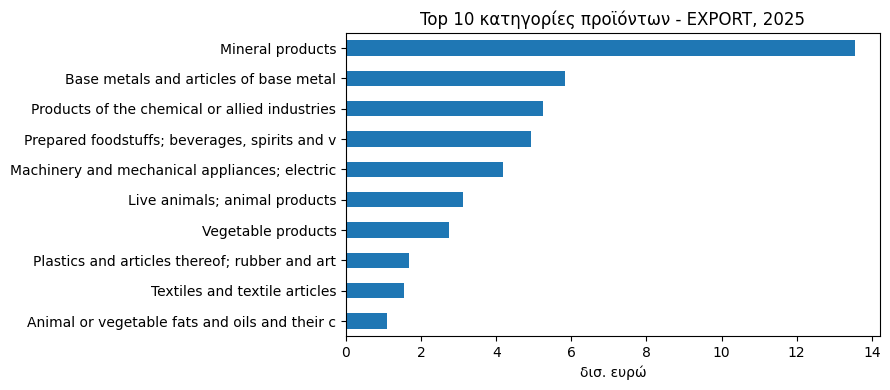

Top 10 κατηγορίες - IMPORT (δισ. ευρώ, 2025)
KATIGORIA
Mineral products                                 16.80
Machinery and mechanical appliances; electric    12.32
Products of the chemical or allied industries    10.20
Base metals and articles of base metal            6.68
Vehicles, aircraft, vessels and associated tr     6.12
Prepared foodstuffs; beverages, spirits and v     4.81
Live animals; animal products                     4.47
Plastics and articles thereof; rubber and art     3.58
Textiles and textile articles                     3.45
Vegetable products                                2.92
Name: INDICATOR_VALUE, dtype: float64



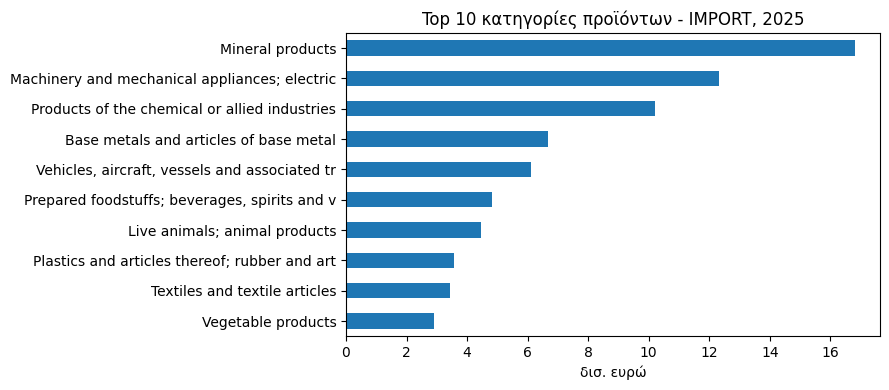

In [37]:
xwres = df[df["typos"] == "χώρα"].copy()
xwres["KATIGORIA"] = xwres["PRODUCT_LAB"].str.split(" (", n=1, regex=False).str[0].str[:45]

for roi in ["EXPORT", "IMPORT"]:
    top = (xwres[xwres["FLOW_LAB"] == roi]
           .groupby("KATIGORIA")["INDICATOR_VALUE"].sum()
           .sort_values(ascending=False).head(10) / 1e9)
    print("Top 10 κατηγορίες -", roi, "(δισ. ευρώ, 2025)")
    print(top.round(2))
    print()

    top.sort_values().plot(kind="barh", figsize=(9, 4))
    plt.title("Top 10 κατηγορίες προϊόντων - " + roi + ", 2025")
    plt.xlabel("δισ. ευρώ")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

In [39]:

# Ετησια συνολικη εικονα: χωρες + ειδικες εγγραφες

analysi = df[df["typos"].isin(["χώρα", "ειδικό"])]

etisia = (
    analysi.groupby("FLOW_LAB")["INDICATOR_VALUE"].sum() / 1e9
)

eksagoges = etisia["EXPORT"]
eisagoges = etisia["IMPORT"]

print("ΕΤΗΣΙΟ ΕΜΠΟΡΙΚΟ ΙΣΟΖΥΓΙΟ 2025")
print(f"Εξαγωγές: {eksagoges:.3f} δισ. ευρώ")
print(f"Εισαγωγές: {eisagoges:.3f} δισ. ευρώ")
print(f"Ισοζύγιο: {eksagoges - eisagoges:.3f} δισ. ευρώ")


ΕΤΗΣΙΟ ΕΜΠΟΡΙΚΟ ΙΣΟΖΥΓΙΟ 2025
Εξαγωγές: 48.659 δισ. ευρώ
Εισαγωγές: 82.475 δισ. ευρώ
Ισοζύγιο: -33.816 δισ. ευρώ


In [40]:

analysi = df[df["typos"].isin(["χώρα", "ειδικό"])]

miniaia = (
    analysi.pivot_table(
        index="PERIOD",
        columns="FLOW_LAB",
        values="INDICATOR_VALUE",
        aggfunc="sum"
    ) / 1e9
)

miniaia["ISOZYGIO"] = miniaia["EXPORT"] - miniaia["IMPORT"]

print("ΜΗΝΙΑΙΑ ΣΤΟΙΧΕΙΑ 2025 (δισ. ευρώ)")
print(miniaia.round(3))


ΜΗΝΙΑΙΑ ΣΤΟΙΧΕΙΑ 2025 (δισ. ευρώ)
FLOW_LAB  EXPORT  IMPORT  ISOZYGIO
PERIOD                            
202501     4.122   6.959    -2.837
202502     4.067   6.509    -2.443
202503     3.953   7.134    -3.181
202504     3.831   6.711    -2.881
202505     4.196   6.519    -2.323
202506     3.958   7.149    -3.191
202507     4.374   7.381    -3.007
202508     3.362   5.472    -2.110
202509     4.268   6.980    -2.712
202510     4.279   6.983    -2.704
202511     4.087   6.939    -2.851
202512     4.161   7.739    -3.577


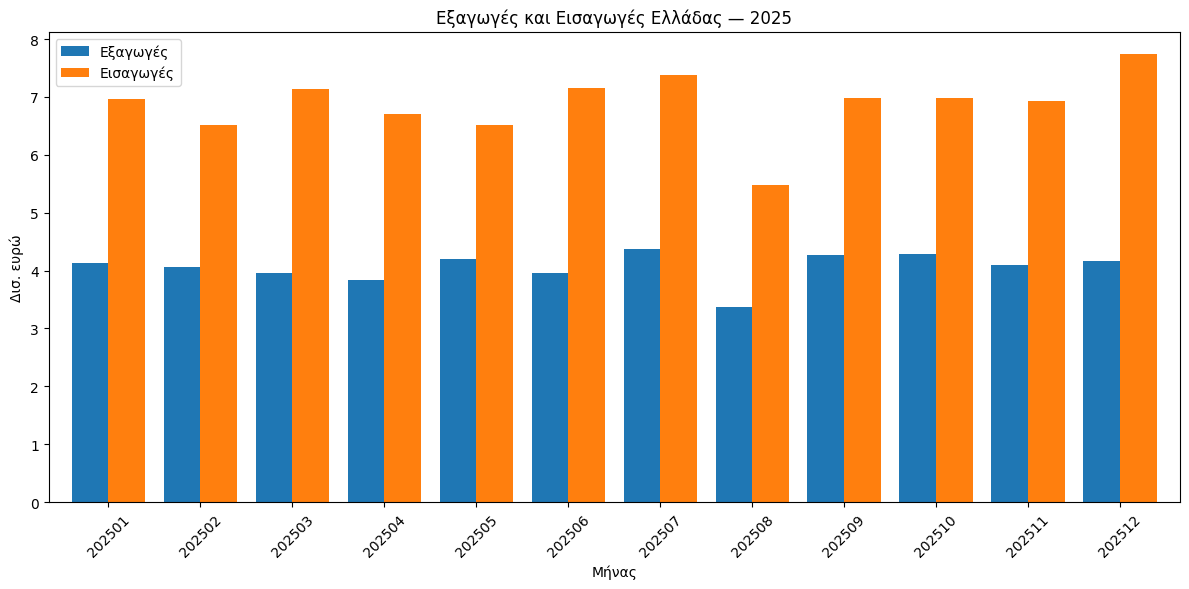

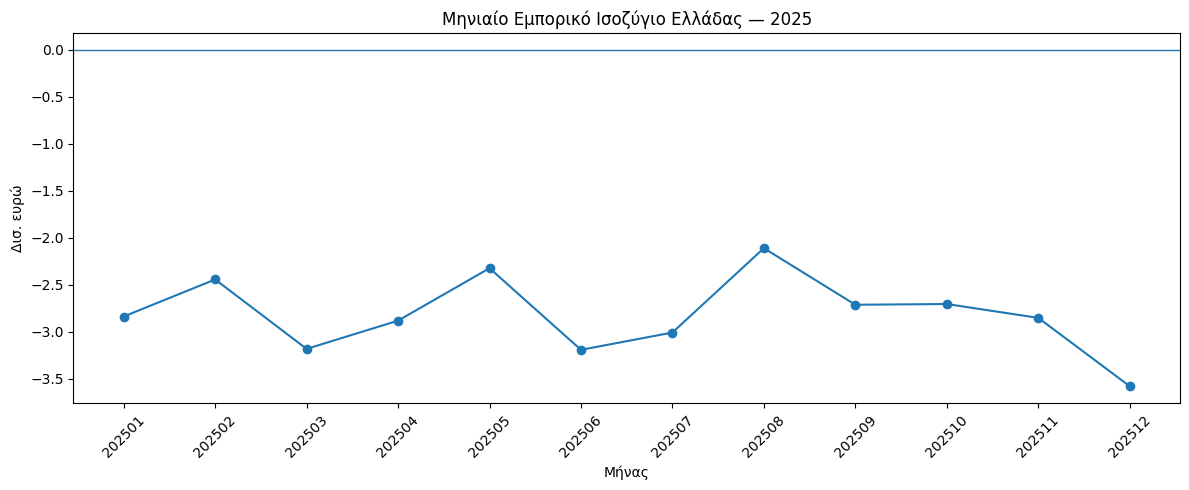

In [42]:

# Μηνιαία εξέλιξη εξαγωγών και εισαγωγών

import matplotlib.pyplot as plt

miniaia.index = miniaia.index.astype(str)

ax = miniaia[["EXPORT", "IMPORT"]].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Εξαγωγές και Εισαγωγές Ελλάδας — 2025")
ax.set_xlabel("Μήνας")
ax.set_ylabel("Δισ. ευρώ")
ax.set_xticklabels(miniaia.index, rotation=45)
ax.legend(["Εξαγωγές", "Εισαγωγές"])

plt.tight_layout()
plt.show()

# Μηνιαίο εμπορικό ισοζύγιο

plt.figure(figsize=(12, 5))
plt.plot(
    miniaia.index,
    miniaia["ISOZYGIO"],
    marker="o"
)
plt.axhline(0, linewidth=1)
plt.title("Μηνιαίο Εμπορικό Ισοζύγιο Ελλάδας — 2025")
plt.xlabel("Μήνας")
plt.ylabel("Δισ. ευρώ")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



# Βασικά ευρήματα — Greek Foreign Trade 2025

## 1. Ετήσιο εμπορικό ισοζύγιο

- Εξαγωγές: €48,659 δισ.
- Εισαγωγές: €82,475 δισ.
- Εμπορικό ισοζύγιο: -€33,816 δισ.

Οι εισαγωγές υπερέβησαν σημαντικά τις εξαγωγές, με κάλυψη εισαγωγών από εξαγωγές περίπου 59%.

## 2. Μηνιαία εξέλιξη

Το εμπορικό ισοζύγιο ήταν αρνητικό και στους 12 μήνες του 2025.

- Μικρότερο έλλειμμα: Αύγουστος.
- Μεγαλύτερο έλλειμμα: Δεκέμβριος.

## 3. Εμπορικοί εταίροι

- Ιταλία: σημαντικότερος προορισμός εξαγωγών.
- Γερμανία: σημαντικότερη χώρα προέλευσης εισαγωγών.
- Κίνα: ένας από τους σημαντικότερους προμηθευτές εισαγωγών.

## 4. Κατηγορίες προϊόντων

Τα ορυκτά προϊόντα αποτελούν την κορυφαία κατηγορία τόσο στις εξαγωγές όσο και στις εισαγωγές.

## 5. Συμπέρασμα

Η ανάλυση αναδεικνύει τη διαχρονική εξάρτηση της ελληνικής αγοράς από τις εισαγωγές και το σημαντικό εμπορικό έλλειμμα κατά το 2025.
